# Phase 4 — Le pré-entraînement

C'est ici que ton modèle apprend le français. **Il faut un GPU** : Exécution → Modifier le type d'exécution → **GPU T4**.

Le principe d'une étape d'entraînement :
1. on prend un lot de morceaux de texte ;
2. le modèle prédit le token suivant à chaque position → on calcule la **perte** ;
3. **la rétropropagation** (`backward`) calcule, pour chacun des 46 M de paramètres, dans quel sens le bouger pour que la perte baisse (le *gradient*) ;
4. **l'optimiseur** (AdamW) fait un petit pas dans ce sens ;
5. on recommence, des milliers de fois.

**Si Colab se déconnecte :** reconnecte-toi, réexécute toutes les cellules dans l'ordre. L'entraînement reprend automatiquement au dernier point de sauvegarde (toutes les 500 étapes, sur ton Drive).

In [1]:
from google.colab import drive
drive.mount('/content/drive')
DOSSIER = "/content/drive/MyDrive/petit-llm"

!pip -q install tokenizers
import os, sys, time, math, shutil, csv
import numpy as np, torch
from tokenizers import Tokenizer
sys.path.append(DOSSIER)
from model import Config, GPT

assert torch.cuda.is_available(), "Pas de GPU ! Exécution -> Modifier le type d'exécution -> GPU T4"
print("GPU :", torch.cuda.get_device_name(0))

# Lire les données depuis le Drive est très lent : on les copie une fois sur le disque local.
for nom in ["train.bin", "val.bin"]:
    if not os.path.exists(f"/content/{nom}"):
        shutil.copy(f"{DOSSIER}/{nom}", f"/content/{nom}")
train = np.memmap("/content/train.bin", dtype=np.uint16, mode="r")
val = np.memmap("/content/val.bin", dtype=np.uint16, mode="r")
tokenizer = Tokenizer.from_file(f"{DOSSIER}/tokenizer.json")
print(f"train : {len(train):,} tokens | val : {len(val):,} tokens")

Mounted at /content/drive
GPU : Tesla T4
train : 536,800,272 tokens | val : 2,770,472 tokens


## 1. Les réglages (hyperparamètres)

- **Taille de lot** : on veut voir beaucoup de texte à chaque pas (~33 000 tokens), mais ça ne tient pas d'un coup dans la mémoire du GPU. On fait donc 4 petits passages de 16 morceaux et on **additionne les gradients** avant de faire le pas (*gradient accumulation*).
- **Nombre d'étapes** : 16 000 étapes × 32 768 tokens ≈ 524 M tokens, soit **un passage complet** sur ton corpus.
- **Taux d'apprentissage** (*learning rate*) : la taille des pas. Il **monte** doucement au début (*warmup*, le modèle est fragile) puis **redescend** en cosinus (sur la fin, on affine avec de petits pas).
- **Précision mixte** : le GPU calcule en 16 bits au lieu de 32, ce qui va environ deux fois plus vite.

In [2]:
MICRO_LOT = 16          # morceaux par passage
T = 512                 # longueur d'un morceau
ACCUMULATION = 4        # passages par étape -> 16 x 512 x 4 = 32 768 tokens par étape
ETAPES = 16_000
LR_MAX, LR_MIN = 6e-4, 6e-5
WARMUP = 500
EVAL_TOUS = 500         # évaluation + sauvegarde toutes les 500 étapes

device = "cuda"
# La T4 calcule en float16 ; les GPU plus récents (A100, L4) en bfloat16, plus stable.
bf16 = torch.cuda.get_device_capability()[0] >= 8
dtype = torch.bfloat16 if bf16 else torch.float16
print("Précision :", dtype)

def lot(donnees):
    debuts = np.random.randint(0, len(donnees) - T - 1, MICRO_LOT)
    x = torch.stack([torch.from_numpy(donnees[i:i + T].astype(np.int64)) for i in debuts])
    y = torch.stack([torch.from_numpy(donnees[i + 1:i + 1 + T].astype(np.int64)) for i in debuts])
    return x.pin_memory().to(device, non_blocking=True), y.pin_memory().to(device, non_blocking=True)

def taux(etape):
    if etape < WARMUP:
        return LR_MAX * (etape + 1) / WARMUP
    avancement = (etape - WARMUP) / max(1, ETAPES - WARMUP)
    return LR_MIN + 0.5 * (LR_MAX - LR_MIN) * (1 + math.cos(math.pi * min(1.0, avancement)))

Précision : torch.float16


## 2. Le modèle, l'optimiseur, et la reprise

**Weight decay** : à chaque pas, AdamW tire légèrement les grandes matrices vers zéro. Ça évite que le modèle s'appuie sur quelques poids énormes, et l'aide à généraliser plutôt qu'à mémoriser. On ne l'applique pas aux petits paramètres de normalisation.

Si une sauvegarde existe sur ton Drive, on la recharge et on reprend à l'étape où on s'était arrêté.

In [3]:
modele = GPT(Config()).to(device)

decay = [p for p in modele.parameters() if p.dim() >= 2]
no_decay = [p for p in modele.parameters() if p.dim() < 2]
optimiseur = torch.optim.AdamW(
    [{"params": decay, "weight_decay": 0.1}, {"params": no_decay, "weight_decay": 0.0}],
    lr=LR_MAX, betas=(0.9, 0.95), fused=True,
)
scaler = torch.amp.GradScaler(enabled=(dtype == torch.float16))

SAUVEGARDE = f"{DOSSIER}/checkpoint.pt"
JOURNAL = f"{DOSSIER}/journal.csv"
etape_depart = 0
if os.path.exists(SAUVEGARDE):
    ck = torch.load(SAUVEGARDE, map_location=device)
    modele.load_state_dict(ck["modele"])
    optimiseur.load_state_dict(ck["optimiseur"])
    scaler.load_state_dict(ck["scaler"])
    etape_depart = ck["etape"]
    print(f"Reprise à l'étape {etape_depart:,}")
else:
    with open(JOURNAL, "w") as f:
        csv.writer(f).writerow(["etape", "perte_train", "perte_val", "lr", "tokens_par_s"])
    print("Nouvel entraînement")

Nouvel entraînement


## 3. Évaluation et exemples

Toutes les 500 étapes :
- **perte de validation** : calculée sur `val.bin`, du texte que le modèle n'a **jamais** vu. Si la perte d'entraînement baisse mais pas celle de validation, il récite au lieu d'apprendre (ton N = 8 !) ;
- **un exemple généré**, pour *voir* le modèle progresser.

In [4]:
@torch.no_grad()
def evaluer(n=40):
    modele.eval()
    pertes = {}
    for nom, donnees in [("train", train), ("val", val)]:
        total = 0.0
        for _ in range(n):
            x, y = lot(donnees)
            with torch.autocast("cuda", dtype=dtype):
                _, perte = modele(x, y)
            total += perte.item()
        pertes[nom] = total / n
    modele.train()
    return pertes

def exemple(debut="La ville de", n=40):
    modele.eval()
    ids = torch.tensor([tokenizer.encode(debut).ids], device=device)
    with torch.autocast("cuda", dtype=dtype):
        sortie = modele.generer(ids, n, temperature=0.8)
    modele.train()
    return tokenizer.decode(sortie[0].tolist())

def sauvegarder(etape):
    ck = {"modele": modele.state_dict(), "optimiseur": optimiseur.state_dict(),
          "scaler": scaler.state_dict(), "etape": etape}
    torch.save(ck, "/content/checkpoint_tmp.pt")              # d'abord en local...
    shutil.copy("/content/checkpoint_tmp.pt", SAUVEGARDE)      # ...puis sur le Drive

print("Avant entraînement :", evaluer(10))
print(exemple())

Avant entraînement : {'train': 9.78795919418335, 'val': 9.787330532073975}
La ville deayantigineuss tuber rendre successeur suivialtAméric contemporainsésiluisit entrantinterdictionThé mots 176 Union Rotterdam2021 �IB fonctionnement Seconde 60 vér RotterdamépendantLien Wy scientifiques neige Ky Ohéan sculpturestud Ste roue Oc


## 4. La boucle d'entraînement

Lance cette cellule et laisse tourner. Toutes les 50 étapes, une ligne : la perte, la vitesse, le temps restant estimé.

**Reste sur l'onglet** de temps en temps : Colab gratuit peut couper une session laissée sans activité. Si ça arrive, pas de panique, tu reprendras au dernier point de sauvegarde.

Ce que tu devrais voir : la perte part de ~9,7, chute très vite les premières centaines d'étapes (le modèle apprend les mots fréquents, la ponctuation), puis descend de plus en plus lentement (la grammaire, puis le sens).

In [5]:
modele.train()
t0, tokens_vus = time.time(), 0
for etape in range(etape_depart, ETAPES):
    lr = taux(etape)
    for g in optimiseur.param_groups:
        g["lr"] = lr

    for _ in range(ACCUMULATION):
        x, y = lot(train)
        with torch.autocast("cuda", dtype=dtype):
            _, perte = modele(x, y)
        scaler.scale(perte / ACCUMULATION).backward()      # 3. rétropropagation
    scaler.unscale_(optimiseur)
    torch.nn.utils.clip_grad_norm_(modele.parameters(), 1.0)  # on évite les pas trop violents
    scaler.step(optimiseur)                                  # 4. le pas
    scaler.update()
    optimiseur.zero_grad(set_to_none=True)
    tokens_vus += MICRO_LOT * T * ACCUMULATION

    if etape % 50 == 0:
        vitesse = tokens_vus / (time.time() - t0)
        restant = (ETAPES - etape) * MICRO_LOT * T * ACCUMULATION / vitesse
        print(f"étape {etape:>6,} | perte {perte.item():.3f} | lr {lr:.1e} | "
              f"{vitesse:,.0f} tokens/s | reste ~{restant / 3600:.1f} h")

    if (etape + 1) % EVAL_TOUS == 0:
        p = evaluer()
        print(f"\n=== étape {etape + 1:,} | perte train {p['train']:.3f} | perte VAL {p['val']:.3f} ===")
        print("Exemple :", exemple(), "\n")
        with open(JOURNAL, "a") as f:
            csv.writer(f).writerow([etape + 1, round(p["train"], 4), round(p["val"], 4), lr, round(vitesse)])
        sauvegarder(etape + 1)

print("Entraînement terminé !")
torch.save(modele.state_dict(), f"{DOSSIER}/modele_final.pt")

étape      0 | perte 9.785 | lr 1.2e-06 | 33,995 tokens/s | reste ~4.3 h
étape     50 | perte 8.002 | lr 6.1e-05 | 44,847 tokens/s | reste ~3.2 h
étape    100 | perte 6.866 | lr 1.2e-04 | 44,110 tokens/s | reste ~3.3 h
étape    150 | perte 6.395 | lr 1.8e-04 | 43,222 tokens/s | reste ~3.3 h
étape    200 | perte 5.894 | lr 2.4e-04 | 41,313 tokens/s | reste ~3.5 h
étape    250 | perte 5.777 | lr 3.0e-04 | 40,469 tokens/s | reste ~3.5 h
étape    300 | perte 5.408 | lr 3.6e-04 | 39,802 tokens/s | reste ~3.6 h
étape    350 | perte 5.457 | lr 4.2e-04 | 39,381 tokens/s | reste ~3.6 h
étape    400 | perte 5.248 | lr 4.8e-04 | 39,065 tokens/s | reste ~3.6 h
étape    450 | perte 5.064 | lr 5.4e-04 | 38,813 tokens/s | reste ~3.6 h

=== étape 500 | perte train 4.991 | perte VAL 4.965 ===
Exemple : La ville de France.

Au , le département de la Nouvelle-Monton-Dame-président de Guérovet-Denis-Soulet-de-de-Bard-Dassot 

étape    500 | perte 5.168 | lr 6.0e-04 | 37,606 tokens/s | reste ~3.8 h
étape  

## 5. La courbe d'apprentissage

À lancer quand tu veux (même en cours de route, dans une autre session) : elle lit le journal sur ton Drive.

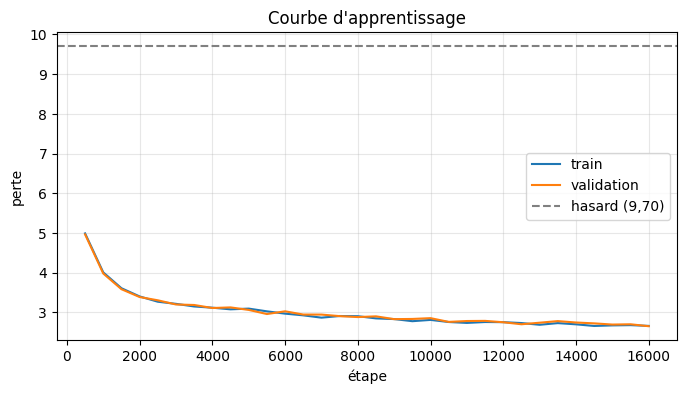

,etape,perte_train,perte_val,lr,tokens_par_s
27,14000,2.7007,2.7464,0.000082,35946
28,14500,2.6595,2.7250,0.000072,35947
29,15000,2.6739,2.6948,0.000066,35925
30,15500,2.6802,2.7020,0.000061,35920
31,16000,2.6613,2.6530,0.000060,35923


In [6]:
import pandas as pd, matplotlib.pyplot as plt
j = pd.read_csv(JOURNAL)
plt.figure(figsize=(8, 4))
plt.plot(j.etape, j.perte_train, label="train")
plt.plot(j.etape, j.perte_val, label="validation")
plt.axhline(math.log(16384), ls="--", c="gray", label="hasard (9,70)")
plt.xlabel("étape"); plt.ylabel("perte"); plt.legend(); plt.grid(alpha=.3)
plt.title("Courbe d'apprentissage")
plt.show()
j.tail()

## 6. Jouer avec le modèle

In [7]:
for debut in ["La ville de", "Victor Hugo est", "En 1789,", "Le chat"]:
    print(exemple(debut, 60), "\n" + "-" * 60)

La ville de Haguenau est le nom du village dont la construction remonte à l'époque du comte de Saint-Gobain.

Histoire

La première mention écrite de Haguenau remonte à 1252. Haguenau est mentionné dans un document de 1172 sous le nom 
------------------------------------------------------------
Victor Hugo est une peinture de l'artiste belge François-Xavier Fratellini réalisée en 1533.

Histoire 
Cette peinture de l'artiste, intitulée Hercule du matin, remonte à l'époque de la République romaine, quand le peintre Hercule du matin était pris en 
------------------------------------------------------------
En 1789, le roi nomme un lieutenant-colonel chargé de la défense du quartier du Rhin à l'artillerie de l'armée du Rhin, il reçoit le commandement de la place-forte du Rhin. Il est blessé lors de la bataille de Rhin le 6 août suivant. Le 11 septembre 1789, il est 
------------------------------------------------------------
Le chat est un animal qui porte un masque dans sa peau et qui 